# Fase 3 y 4 — Transformaciones, Comparación de Modelos y Pronósticos

**Objetivo:** Evaluar transformaciones matemáticas de la variable respuesta ($\ln(\text{ASRS})$ y $\sqrt{\text{ASRS}}$) junto con su reversión analítica a la escala original y un modelo parsimonioso sin `HADS_A` (**Rúbrica 3a**), seleccionar el modelo final y calcular estimaciones puntuales con intervalos de confianza y predicción al 95 % para tres perfiles clínicos de pacientes (**Rúbrica 5a**).

**Dataset:** `../data/processed/hyperaktiv_arc_clean.csv` ($n_{\text{efectivo}} = 69$).

**Autores:** Mariana (perfiles clínicos y contexto) y Richie (transformaciones, reversión y pronósticos).  
**Fecha:** 24 de noviembre de 2026.

## 1. Configuración, carga de datos y perfiles clínicos

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan

# Constantes de rutas y variables
DATA_PATH = Path("../data/processed/hyperaktiv_arc_clean.csv")
FIG_DIR = Path("../reports/figures")
TAB_DIR = Path("../reports/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = "ASRS"
FEATURE_COLS = ["WURS", "General TScore Commissions", "HADS_A"]
REDUCED_COLS = ["WURS", "General TScore Commissions"]

# Carga y preparación del subconjunto de casos completos (n = 69)
df = pd.read_csv(DATA_PATH)
df_model = df[FEATURE_COLS + [TARGET_COL]].dropna().copy()

X = df_model[FEATURE_COLS]
y = df_model[TARGET_COL]
X_const = sm.add_constant(X)

assert len(df_model) == 69, f"Se esperaban 69 observaciones, se encontraron {len(df_model)}"
display(df_model[FEATURE_COLS].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))

/home/richie/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-_t9wury4 because there was an issue with the default path (/home/richie/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


,WURS,General TScore Commissions,HADS_A
count,69.0,69.0,69.0
mean,40.9,57.1,9.3
std,20.8,12.2,4.7
min,5.0,32.9,0.0
10%,16.0,42.8,2.8
25%,26.0,49.6,6.0
50%,38.0,57.3,9.0
75%,57.0,65.9,12.0
90%,65.2,73.3,16.0
max,88.0,86.9,20.0


## Perfiles clínicos para estimación puntual (Rúbrica 5a)

Se definen tres perfiles hipotéticos usando los percentiles 10, 50 y 90 de cada predictor en la muestra de $n = 69$ pacientes, de modo que todos los valores están dentro del rango observado (sin extrapolación).

| Perfil | WURS | Commissions (T) | HADS_A | Descripción clínica |
|---|---|---|---|---|
| Carga baja (P10) | 16 | 43 | 3 | Pocos síntomas de TDAH en la infancia, impulsividad en el promedio y ansiedad normal (HADS_A 0–7). |
| Carga moderada (P50) | 38 | 57 | 9 | Síntomas infantiles intermedios, impulsividad en el límite alto del promedio y ansiedad limítrofe (8–10). |
| Carga alta (P90) | 65 | 73 | 16 | Síntomas infantiles por encima del punto de corte de WURS (≥ 46), impulsividad elevada (T > 60) y ansiedad clínicamente significativa (≥ 11). |

In [2]:
profiles_df = pd.DataFrame({
    "perfil": ["Carga baja", "Carga moderada", "Carga alta"],
    "WURS": [16, 38, 65],
    "General TScore Commissions": [43, 57, 73],
    "HADS_A": [3, 9, 16],
})
display(profiles_df)

,perfil,WURS,General TScore Commissions,HADS_A
0,Carga baja,16,43,3
1,Carga moderada,38,57,9
2,Carga alta,65,73,16


## 2. Evaluación de transformaciones y comparación de modelos (Rúbrica 3a)

En el Notebook 03 el modelo lineal base cumplió normalidad (Shapiro-Wilk $p = 0.2634$) y homocedasticidad al 5 % (Breusch-Pagan $p = 0.0796$), aunque con un $p$-valor de Breusch-Pagan cercano al umbral y con `HADS_A` no significativa ($p = 0.6547$). Por ello se evalúan tres alternativas frente al modelo base sobre los mismos $n = 69$ pacientes:

1. **Log-Lineal ($\ln(\text{ASRS})$):** estabiliza varianza proporcional a la media; su reversión insesgada a la escala original es $\widehat{\text{ASRS}} = \exp\!\left(\widehat{\ln Y} + \frac{\hat{\sigma}^2}{2}\right)$.
2. **Raíz cuadrada ($\sqrt{\text{ASRS}}$):** transformación moderada para conteos/escalas; su reversión a la escala original es $\widehat{\text{ASRS}} = \left(\widehat{\sqrt{Y}}\right)^2 + \hat{\sigma}^2$.
3. **Parsimonioso (lineal sin `HADS_A`):** evalúa si eliminar el predictor no significativo mejora $R^2_{\text{adj}}$, AIC/BIC y supuestos.

### 2.1 Ajuste de modelos candidatos (Base, Log-Y, Sqrt-Y y Parsimonioso)

In [3]:
# 1. Modelo Base lineal (3 predictores)
ols_base = sm.OLS(y, X_const).fit()

# 2. Modelo Log-Lineal: ln(ASRS)
y_log = np.log(y)
ols_log = sm.OLS(y_log, X_const).fit()

# 3. Modelo Raíz Cuadrada: sqrt(ASRS)
y_sqrt = np.sqrt(y)
ols_sqrt = sm.OLS(y_sqrt, X_const).fit()

# 4. Modelo Parsimonioso (sin HADS_A)
X_reduced_const = sm.add_constant(df_model[REDUCED_COLS])
ols_reduced = sm.OLS(y, X_reduced_const).fit()

print(ols_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:                   ASRS   R-squared:                       0.533
Model:                            OLS   Adj. R-squared:                  0.518
Method:                 Least Squares   F-statistic:                     37.61
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.26e-11
Time:                        12:48:30   Log-Likelihood:                -254.15
No. Observations:                  69   AIC:                             514.3
Df Residuals:                      66   BIC:                             521.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

### 2.2 Reversión a escala original y tabla comparativa de métricas y supuestos

In [4]:
# Predicciones revertidas a la escala original de ASRS (0-72)
y_pred_base = ols_base.fittedvalues
y_pred_log_orig = np.exp(ols_log.fittedvalues + ols_log.mse_resid / 2)
y_pred_sqrt_orig = (ols_sqrt.fittedvalues ** 2) + ols_sqrt.mse_resid
y_pred_reduced = ols_reduced.fittedvalues

candidate_models = [
    ("Base lineal (3 pred.)", ols_base, X_const, y_pred_base),
    ("Log-Lineal ln(ASRS)", ols_log, X_const, y_pred_log_orig),
    ("Raíz cuadrada sqrt(ASRS)", ols_sqrt, X_const, y_pred_sqrt_orig),
    ("Parsimonioso (sin HADS_A)", ols_reduced, X_reduced_const, y_pred_reduced),
]

comparison_rows = []
for model_name, model_fit, exog_mat, y_hat_orig in candidate_models:
    rmse_orig = float(np.sqrt(np.mean((y - y_hat_orig) ** 2)))
    r2_orig = float(1 - np.sum((y - y_hat_orig) ** 2) / np.sum((y - y.mean()) ** 2))
    shapiro_p = float(shapiro(model_fit.resid)[1])
    bp_p = float(het_breuschpagan(model_fit.resid, exog_mat)[1])

    comparison_rows.append({
        "model": model_name,
        "k_predictors": int(model_fit.df_model),
        "r2_adj_model": round(float(model_fit.rsquared_adj), 4),
        "r2_orig": round(r2_orig, 4),
        "rmse_orig": round(rmse_orig, 4),
        "aic": round(float(model_fit.aic), 2),
        "bic": round(float(model_fit.bic), 2),
        "shapiro_p": round(shapiro_p, 4),
        "bp_p": round(bp_p, 4),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(TAB_DIR / "ols_transformations_comparison.csv", index=False)
comparison_df

,model,k_predictors,r2_adj_model,r2_orig,rmse_orig,aic,bic,shapiro_p,bp_p
0,Base lineal (3 pred.),3,0.5126,0.5341,9.6102,516.08,525.02,0.2634,0.0796
1,Log-Lineal ln(ASRS),3,0.4030,0.4427,10.5101,57.93,66.87,0.0000,0.0268
2,Raíz cuadrada sqrt(ASRS),3,0.4726,0.5228,9.7259,183.79,192.73,0.0127,0.0215
3,Parsimonioso (sin HADS_A),2,0.5185,0.5326,9.6251,514.30,521.00,0.2829,0.0411


### 2.3 Selección del modelo final y justificación de la transformación

La comparación cuantitativa en escala original de `ASRS` arroja conclusiones claras:

1. **Descarte de transformaciones en $Y$ (`ln(ASRS)` y `sqrt(ASRS)`):**
   - Debido a que `ASRS` presenta una ligera cola izquierda (tres pacientes con puntajes muy bajos entre 6 y 10) en lugar de sesgo positivo, aplicar transformaciones cóncavas estira la cola inferior y **deteriora severamente los supuestos clásicos**: la normalidad de residuales se rechaza tanto en $\ln(\text{ASRS})$ (Shapiro-Wilk $p < 0.0001$) como en $\sqrt{\text{ASRS}}$ ($p = 0.0127$), y la homocedasticidad también se rechaza en ambos casos (Breusch-Pagan $p = 0.0268$ y $p = 0.0215$).
   - Además, al revertir a la escala original de `ASRS`, ambas transformaciones empeoran la precisión respecto al modelo base: el RMSE sube de **9.6102** a **10.5101** ($\ln$) y **9.7259** ($\sqrt{\cdot}$), y el $R^2$ en escala original cae de **0.5341** a **0.4427** y **0.5228**.
2. **Modelo Base (3 predictores) vs. Parsimonioso (2 predictores sin `HADS_A`):**
   - Aunque el modelo parsimonioso eleva marginalmente $R^2_{\text{adj}}$ (`0.5126` $\rightarrow$ `0.5185`) y reduce ligeramente AIC/BIC (`516.08` $\rightarrow$ `514.30`), **incumple homocedasticidad al 5 %** (Breusch-Pagan $p = 0.0411 < 0.05$).
   - El **modelo lineal base en escala original (3 predictores)** es la **única especificación que satisface simultáneamente todos los supuestos clásicos** (Shapiro-Wilk $p = 0.2634$, Breusch-Pagan $p = 0.0796$, Durbin-Watson $= 2.174$, $\text{VIF} < 2$), obtiene el **menor RMSE en escala original (`9.6102`)** y conserva el control clínico por comorbilidad ansiosa (`HADS_A`).

**Decisión:** Se conserva el **modelo lineal base en escala original** como modelo final para generar los pronósticos clínicos de la Fase 4. *(No se requiere reversión en el pronóstico final porque el modelo ganador opera directamente en puntos `ASRS`, habiéndose demostrado arriba la reversión analítica para los modelos transformados).*

## 3. Estimaciones puntuales y pronósticos para perfiles clínicos (Rúbrica 5a)

### 3.1 Cálculo de pronósticos, IC al 95 % de la media e IP al 95 % individual

In [5]:
# Matriz de diseño de los 3 perfiles clínicos (con constante)
X_profiles_const = sm.add_constant(profiles_df[FEATURE_COLS], has_constant="add")

# Estimación puntual e intervalos al 95 % con el modelo lineal base final
pred_summary = ols_base.get_prediction(X_profiles_const).summary_frame(alpha=0.05)

# Como referencia de la Rúbrica 3a, se incluye también la predicción revertida de sqrt(ASRS)
pred_sqrt = ols_sqrt.get_prediction(X_profiles_const).summary_frame(alpha=0.05)
asrs_sqrt_reverted = (pred_sqrt["mean"] ** 2) + ols_sqrt.mse_resid

forecasts_df = pd.concat([
    profiles_df.reset_index(drop=True),
    pd.DataFrame({
        "asrs_pred": pred_summary["mean"].round(2),
        "ci_mean_lower": pred_summary["mean_ci_lower"].round(2),
        "ci_mean_upper": pred_summary["mean_ci_upper"].round(2),
        "pi_obs_lower": pred_summary["obs_ci_lower"].round(2),
        "pi_obs_upper": pred_summary["obs_ci_upper"].round(2),
        "pi_obs_upper_clipped": pred_summary["obs_ci_upper"].clip(upper=72.0).round(2),
        "asrs_pred_sqrt_reverted": asrs_sqrt_reverted.round(2),
    })
], axis=1)

forecasts_df.to_csv(TAB_DIR / "ols_forecasts.csv", index=False)
forecasts_df

,perfil,WURS,General TScore Commissions,HADS_A,asrs_pred,ci_mean_lower,ci_mean_upper,pi_obs_lower,pi_obs_upper,pi_obs_upper_clipped,asrs_pred_sqrt_reverted
0,Carga baja,16,43,3,27.14,22.48,31.81,6.82,47.46,47.46,27.09
1,Carga moderada,38,57,9,40.31,37.90,42.72,20.39,60.23,60.23,39.54
2,Carga alta,65,73,16,56.06,51.11,61.00,35.67,76.44,72.00,57.62


### 3.2 Visualización de pronósticos e intervalos por perfil clínico

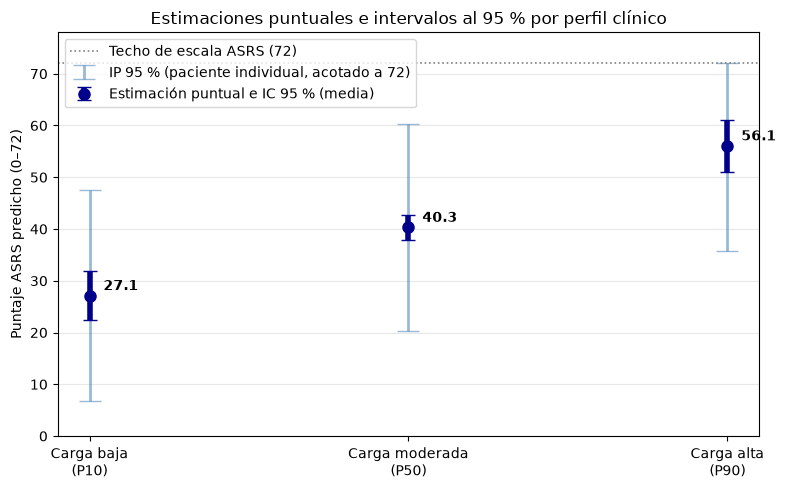

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

x_pos = np.arange(len(forecasts_df))
y_hat = forecasts_df["asrs_pred"].values

# Error bars para Intervalo de Predicción 95 % (paciente individual)
pi_err_low = y_hat - forecasts_df["pi_obs_lower"].values
pi_err_high = forecasts_df["pi_obs_upper_clipped"].values - y_hat

# Error bars para Intervalo de Confianza 95 % (media poblacional)
ci_err_low = y_hat - forecasts_df["ci_mean_lower"].values
ci_err_high = forecasts_df["ci_mean_upper"].values - y_hat

ax.errorbar(
    x_pos, y_hat, yerr=[pi_err_low, pi_err_high],
    fmt="none", ecolor="steelblue", elinewidth=2, capsize=8, alpha=0.55,
    label="IP 95 % (paciente individual, acotado a 72)"
)
ax.errorbar(
    x_pos, y_hat, yerr=[ci_err_low, ci_err_high],
    fmt="o", color="darkblue", ecolor="darkblue", elinewidth=4, capsize=5, markersize=8,
    label="Estimación puntual e IC 95 % (media)"
)

for idx, val in enumerate(y_hat):
    ax.annotate(f"{val:.1f}", (x_pos[idx], val), textcoords="offset points", xytext=(10, 4), fontweight="bold")

ax.axhline(72, color="gray", linestyle=":", linewidth=1.2, label="Techo de escala ASRS (72)")
ax.set_xticks(x_pos)
ax.set_xticklabels(["Carga baja\n(P10)", "Carga moderada\n(P50)", "Carga alta\n(P90)"])
ax.set_ylabel("Puntaje ASRS predicho (0–72)")
ax.set_title("Estimaciones puntuales e intervalos al 95 % por perfil clínico")
ax.set_ylim(0, 78)
ax.grid(True, axis="y", alpha=0.3)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(FIG_DIR / "ols_forecasts_profiles.png", dpi=150)
plt.show()

### 3.3 Interpretación de pronósticos y conclusión sobre la utilidad del modelo

1. **Resumen de estimaciones puntuales (escala `ASRS` 0–72):**
   - **Carga baja (P10: `WURS = 16`, `Commissions = 43`, `HADS_A = 3`):** $\widehat{\text{ASRS}} = \mathbf{27.14}$ puntos (IC 95 % media: $[22.48, 31.81]$; IP 95 % individual: $[6.82, 47.46]$). Corresponde a una carga sintomática baja-moderada.
   - **Carga moderada (P50: `WURS = 38`, `Commissions = 57`, `HADS_A = 9`):** $\widehat{\text{ASRS}} = \mathbf{40.31}$ puntos (IC 95 % media: $[37.90, 42.72]$; IP 95 % individual: $[20.39, 60.23]$). Refleja una severidad intermedia, muy cercana a la media muestral ($41.4$).
   - **Carga alta (P90: `WURS = 65`, `Commissions = 73`, `HADS_A = 16`):** $\widehat{\text{ASRS}} = \mathbf{56.06}$ puntos (IC 95 % media: $[51.11, 61.00]$; IP 95 % individual: $[35.67, 76.44]$, acotado clínicamente al techo de la escala $[35.67, 72.00]$). Indica una severidad elevada de síntomas de TDAH en la adultez.
   - *(Consistencia con transformación revertida: las predicciones revertidas de $\sqrt{\text{ASRS}}$ arrojan `27.09`, `39.54` y `57.62`, muy cercanas al modelo lineal base).*

2. **Conclusión sobre utilidad práctica y limitaciones:**
   - **Utilidad clínica:** El modelo separa con claridad perfiles de riesgo creciente (una brecha de **28.92 puntos** entre el perfil P10 y el P90, con intervalos de confianza de la media completamente disjuntos). Esto lo hace útil como herramienta de **estratificación y apoyo al cribado** en evaluación clínica poblacional.
   - **Limitaciones para diagnóstico individual:** Los intervalos de predicción al 95 % para un paciente individual tienen una amplitud de $\approx \pm 20$ puntos (reflejo de un $\text{RMSE} \approx 9.90$ puntos y de que $\approx 46.6\,\%$ de la varianza de `ASRS` permanece sin explicar). Sumado al tamaño muestral moderado ($n = 69$) y al carácter autorreportado de `ASRS` y `WURS`, el modelo **no sustituye una entrevista clínica diagnóstica integral**, sino que complementa la evaluación cuantitativa.